<a href="https://colab.research.google.com/github/anshhthakur002/numpy_-project/blob/main/Sales_Data_Filter_%26_Report_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=2)
np.random.seed(42)

STORE_COUNT = 10
MONTH_COUNT = 12
MONTHS = np.arange(1, MONTH_COUNT + 1)
MONTH_NAMES = np.array([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

print("NumPy version:", np.__version__)
print("Stores:", STORE_COUNT, "| Months:", MONTH_COUNT)

NumPy version: 2.1.3
Stores: 10 | Months: 12


In [3]:
# Sales are simulated in currency units (CU), not real business data.
# Rows = stores; columns = months.
sales = np.random.randint(18_000, 75_001, size=(STORE_COUNT, MONTH_COUNT))

store_names = np.array([f"Store_{i:02d}" for i in range(1, STORE_COUNT + 1)])
sales_df = pd.DataFrame(sales, index=store_names, columns=MONTH_NAMES)

print("Sales array shape:", sales.shape)
print("Dimensions:", sales.ndim)
print("Data type:", sales.dtype)
print("\nFirst 5 stores:")
display(sales_df.head())

Sales array shape: (10, 12)
Dimensions: 2
Data type: int64

First 5 stores:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Store_01,74422,33795,18860,56158,72343,62732,29284,72886,24265,34850,55194,39962
Store_02,65191,62131,34023,59090,19685,18769,74101,20433,23311,55819,57188,35568
Store_03,71707,37769,46693,24396,45480,59434,43658,36942,36431,20747,18189,37118
Store_04,53773,71810,19899,74886,19267,49551,68680,29394,21556,21890,59606,48740
Store_05,32502,39777,28627,26792,61323,61021,26433,61001,29016,41897,20612,74193


In [4]:
store_totals = sales.sum(axis=1)
store_averages = sales.mean(axis=1)
monthly_totals = sales.sum(axis=0)
monthly_averages = sales.mean(axis=0)

summary_df = pd.DataFrame({
    "Annual Sales (CU)": store_totals,
    "Monthly Average (CU)": store_averages
}, index=store_names).sort_values("Annual Sales (CU)", ascending=False)

print("Highest-revenue store:", store_names[np.argmax(store_totals)])
print("Highest annual sales:", f"{store_totals.max():,.0f} CU")
print("Lowest-revenue store:", store_names[np.argmin(store_totals)])
print("Lowest annual sales:", f"{store_totals.min():,.0f} CU")
display(summary_df.round(2))

Highest-revenue store: Store_06
Highest annual sales: 583,710 CU
Lowest-revenue store: Store_09
Lowest annual sales: 465,227 CU


,Annual Sales (CU),Monthly Average (CU)
Store_06,583710,48642.50
Store_10,581587,48465.58
Store_01,574751,47895.92
Store_04,539052,44921.00
Store_08,533921,44493.42
Store_02,525309,43775.75
Store_05,503194,41932.83
Store_07,490810,40900.83
Store_03,478564,39880.33
Store_09,465227,38768.92


In [5]:
# Each quarter is a 3-column slice of the 12-month array.
quarters = {
    "Q1 (Jan-Mar)": sales[:, 0:3],
    "Q2 (Apr-Jun)": sales[:, 3:6],
    "Q3 (Jul-Sep)": sales[:, 6:9],
    "Q4 (Oct-Dec)": sales[:, 9:12]
}

quarterly_totals = {
    quarter: values.sum(axis=1)
    for quarter, values in quarters.items()
}
quarterly_df = pd.DataFrame(quarterly_totals, index=store_names)
quarterly_df["Annual Total"] = quarterly_df.sum(axis=1)

print("Quarterly sales per store:")
display(quarterly_df.round(0).astype("int64"))
print("Overall quarter totals:")
display(pd.Series({q: arr.sum() for q, arr in quarters.items()},
                  name="Total Sales (CU)").to_frame())

Quarterly sales per store:


,Q1 (Jan-Mar),Q2 (Apr-Jun),Q3 (Jul-Sep),Q4 (Oct-Dec),Annual Total
Store_01,127077,191233,126435,130006,574751
Store_02,161345,97544,117845,148575,525309
Store_03,156169,129310,117031,76054,478564
Store_04,145482,143704,119630,130236,539052
Store_05,100906,149136,116450,136702,503194
Store_06,187508,164688,145455,86059,583710
Store_07,98417,122643,157444,112306,490810
Store_08,117783,131903,149375,134860,533921
Store_09,125823,89059,108699,141646,465227
Store_10,192474,146326,113337,129450,581587


Overall quarter totals:


,Total Sales (CU)
Q1 (Jan-Mar),1412984
Q2 (Apr-Jun),1365546
Q3 (Jul-Sep),1271701
Q4 (Oct-Dec),1225894


In [6]:
# Example business rules; change these thresholds for your own scenario.
monthly_target = 45_000
store_avg_target = 45_000

# All store-month cells that exceed the monthly target.
above_target_mask = sales > monthly_target
above_target_rows, above_target_cols = np.where(above_target_mask)

above_target_records = pd.DataFrame({
    "Store": store_names[above_target_rows],
    "Month": MONTH_NAMES[above_target_cols],
    "Sales (CU)": sales[above_target_mask]
}).sort_values("Sales (CU)", ascending=False)

# Stores whose annual monthly average is below the target.
below_average_mask = store_averages < store_avg_target
below_target_stores = store_names[below_average_mask]

# Combined condition: stores with annual sales above the overall store average
# AND at least one month exceeding the monthly target.
overall_store_average = store_totals.mean()
high_performing_mask = (store_totals > overall_store_average) & above_target_mask.any(axis=1)

# OR condition: stores with either a low annual average or at least one month > 65,000.
high_spike_mask = (store_averages < store_avg_target) | (sales > 65_000).any(axis=1)

print(f"Store-month records above {monthly_target:,} CU:", int(above_target_mask.sum()))
print("Stores below monthly-average target:", below_target_stores.tolist())
print("Above-average annual sales AND target month:", store_names[high_performing_mask].tolist())
print("Low average OR at least one month above 65,000 CU:", store_names[high_spike_mask].tolist())
print("\nTop above-target records:")
display(above_target_records.head(10))

Store-month records above 45,000 CU: 52
Stores below monthly-average target: ['Store_02', 'Store_03', 'Store_04', 'Store_05', 'Store_07', 'Store_08', 'Store_09']
Above-average annual sales AND target month: ['Store_01', 'Store_04', 'Store_06', 'Store_08', 'Store_10']
Low average OR at least one month above 65,000 CU: ['Store_01', 'Store_02', 'Store_03', 'Store_04', 'Store_05', 'Store_06', 'Store_07', 'Store_08', 'Store_09', 'Store_10']

Top above-target records:


,Store,Month,Sales (CU)
18,Store_04,Apr,74886
0,Store_01,Jan,74422
26,Store_05,Dec,74193
9,Store_02,Jul,74101
42,Store_08,Dec,73591
27,Store_06,Jan,73387
4,Store_01,Aug,72886
28,Store_06,Feb,72638
50,Store_10,Jul,72615
2,Store_01,May,72343


In [7]:
# PDF example: select stores at zero-based indices [1, 4, 7].
selected_indices = np.array([1, 4, 7])
selected_store_sales = sales[selected_indices, :]
selected_stores_df = pd.DataFrame(
    selected_store_sales,
    index=store_names[selected_indices],
    columns=MONTH_NAMES
)

# Select the top 3 months by total sales across all stores.
top3_month_indices = np.argsort(monthly_totals)[-3:][::-1]
top3_months_df = pd.DataFrame({
    "Month": MONTH_NAMES[top3_month_indices],
    "Total Sales (CU)": monthly_totals[top3_month_indices],
    "Average per Store (CU)": monthly_averages[top3_month_indices]
})

print("Selected stores (indices 1, 4, 7):")
display(selected_stores_df)
print("Top 3 months by total sales:")
display(top3_months_df.round(2))



Selected stores (indices 1, 4, 7):


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Store_02,65191,62131,34023,59090,19685,18769,74101,20433,23311,55819,57188,35568
Store_05,32502,39777,28627,26792,61323,61021,26433,61001,29016,41897,20612,74193
Store_08,18161,55065,44557,51763,50606,29534,47127,58397,43851,19016,42253,73591


Top 3 months by total sales:


,Month,Total Sales (CU),Average per Store (CU)
0,Jul,531158,53115.8
1,Jan,529402,52940.2
2,Feb,520903,52090.3


In [8]:
# Illustrative monthly target path from 40,000 to 55,000 CU per store.
monthly_growth_targets = np.linspace(40_000, 55_000, MONTH_COUNT)
target_comparison = pd.DataFrame({
    "Month": MONTH_NAMES,
    "Actual Average (CU)": monthly_averages,
    "Target (CU)": monthly_growth_targets,
    "Difference (CU)": monthly_averages - monthly_growth_targets,
    "Met Target": monthly_averages >= monthly_growth_targets
})

print("Months where average store sales met the target:")
print(target_comparison.loc[target_comparison["Met Target"], "Month"].tolist())
display(target_comparison.round(2))



Months where average store sales met the target:
['Jan', 'Feb', 'Apr', 'May', 'Jul']


,Month,Actual Average (CU),Target (CU),Difference (CU),Met Target
0,Jan,52940.2,40000.00,12940.20,True
1,Feb,52090.3,41363.64,10726.66,True
2,Mar,36267.9,42727.27,-6459.37,False
3,Apr,48280.6,44090.91,4189.69,True
4,May,45947.2,45454.55,492.65,True
5,Jun,42326.8,46818.18,-4491.38,False
6,Jul,53115.8,48181.82,4933.98,True
7,Aug,42056.3,49545.45,-7489.15,False
8,Sep,31998.0,50909.09,-18911.09,False
9,Oct,42579.7,52272.73,-9693.03,False


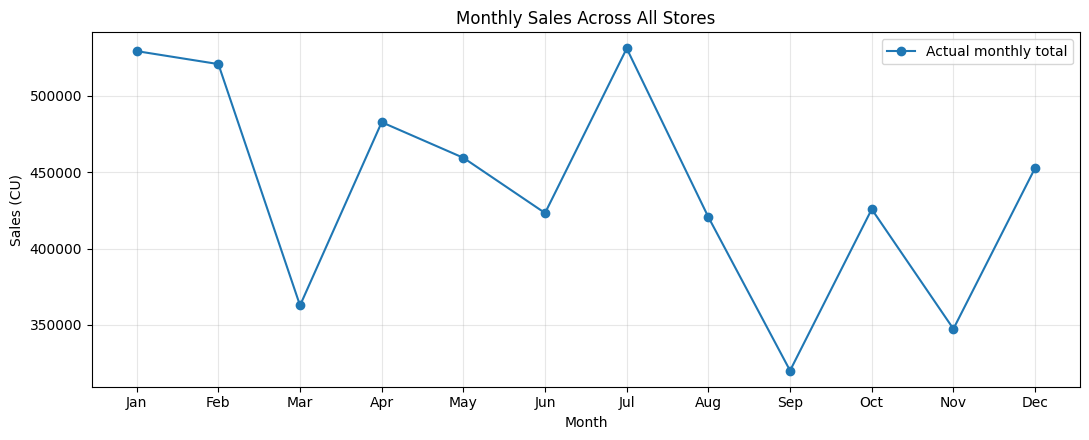

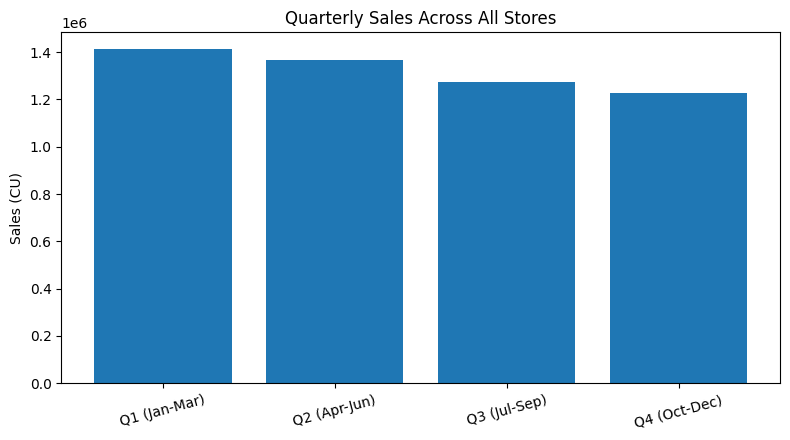

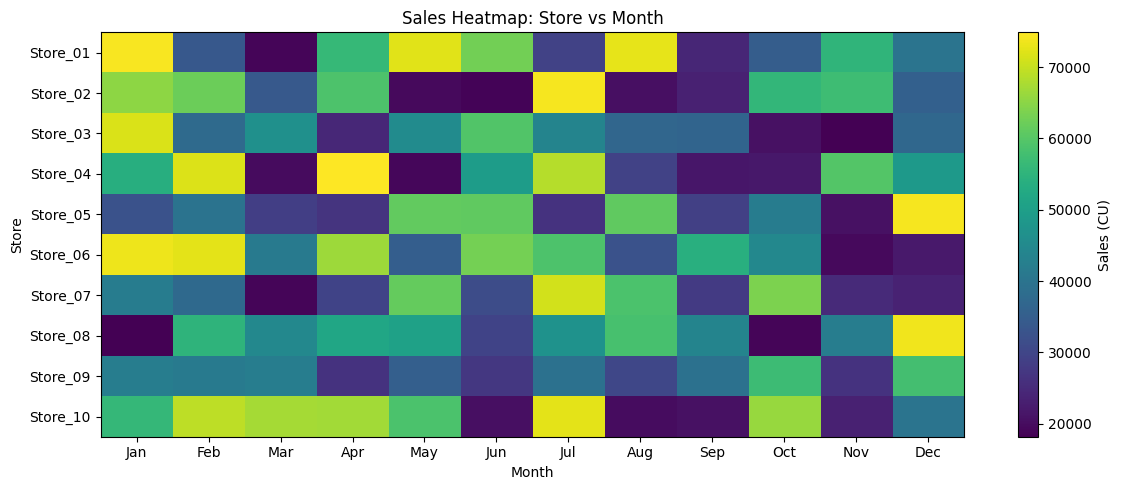

In [9]:
# Monthly total sales
plt.figure(figsize=(11, 4.5))
plt.plot(MONTH_NAMES, monthly_totals, marker="o", label="Actual monthly total")
plt.title("Monthly Sales Across All Stores")
plt.xlabel("Month")
plt.ylabel("Sales (CU)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Quarterly totals
quarter_names = list(quarters.keys())
quarter_values = [quarters[q].sum() for q in quarter_names]
plt.figure(figsize=(8, 4.5))
plt.bar(quarter_names, quarter_values)
plt.title("Quarterly Sales Across All Stores")
plt.ylabel("Sales (CU)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Store-by-month heatmap
plt.figure(figsize=(12, 5))
plt.imshow(sales, aspect="auto")
plt.colorbar(label="Sales (CU)")
plt.xticks(np.arange(MONTH_COUNT), MONTH_NAMES)
plt.yticks(np.arange(STORE_COUNT), store_names)
plt.title("Sales Heatmap: Store vs Month")
plt.xlabel("Month")
plt.ylabel("Store")
plt.tight_layout()
plt.show()


In [10]:
# Download these files from the Colab Files panel.
sales_df.to_csv("monthly_sales_data.csv")
summary_df.to_csv("store_summary.csv")
quarterly_df.to_csv("quarterly_sales_report.csv")
above_target_records.to_csv("above_target_records.csv", index=False)
target_comparison.to_csv("monthly_target_comparison.csv", index=False)

print("Exported 5 CSV report files.")

Exported 5 CSV report files.


In [11]:
# Small checks help catch shape and report errors.
assert sales.shape == (STORE_COUNT, MONTH_COUNT)
assert sales.ndim == 2
assert np.all(sales >= 18_000) and np.all(sales <= 75_000)
assert np.array_equal(store_totals, sales.sum(axis=1))
assert sum(arr.sum() for arr in quarters.values()) == sales.sum()

print("All validation checks passed.")
print(f"Total simulated annual sales: {sales.sum():,} CU")
print(f"Average monthly sales across all stores: {monthly_totals.mean():,.2f} CU")


All validation checks passed.
Total simulated annual sales: 5,276,125 CU
Average monthly sales across all stores: 439,677.08 CU


In [12]:
# This project demonstrates NumPy array creation, shape/dtype inspection, aggregation, 2D slicing, Boolean masking with `&` and `|`, `np.where`, fancy indexing, `np.argsort`, and `np.linspace`. Pandas is used only to format reports, Matplotlib for charts, and CSV exports make the results easy to share.
#
# ### Resume description
# Built a NumPy-based sales reporting engine for 10 stores across 12 months, using quarterly slicing, combined Boolean masks, fancy indexing, target comparisons, visualizations, and CSV report exports.
#
# ### Notes
# - Sales values are randomly generated for learning and are not real company data.
# - Store indices are zero-based, so `[1, 4, 7]` means the second, fifth, and eighth stores.
# - Run all cells in order. If you rerun the data-generation cell, the fixed seed reproduces the same dataset.